In [4]:
import matplotlib.pyplot as plt
import networkx as nx
import h5py
import numpy as np
import pandas as pd
import re
import os
import sys

import mouse1d_analysis as m1da

sys.path.append("/../../HALnalysis")
import analysis_package as mla

from mouse1d_analysis import Burst

import regex as re

In [5]:
#Get bursts from raw data
homedir=os.path.expanduser("~")

filepath = "/run/user/1001/gvfs/smb-share:server=rstore.it.tufts.edu,share=as_rsch_levinlab_wclawson01$/Experimental Data/Summer 2024/mouse_1d/7-9 mouse_1d_test/7/well4/"
filepath = "/run/user/1001/gvfs/smb-share:server=rstore.it.tufts.edu,share=as_rsch_levinlab_wclawson01$/Experimental Data/Summer 2024/mouse_1d/2h_7-12/M07484/240712/4/well4/"
filepath = "/run/user/1001/gvfs/smb-share:server=rstore.it.tufts.edu,share=as_rsch_levinlab_wclawson01$/Experimental Data/Summer 2024/mouse_1d/DIV13/M07475/240716/0/well1/"

filename = "DIV13_well_1"
#filename = "2h_well_4"
filetag = ".raw.h5"
datapath = homedir + "/Documents/HAL/data/wes_analysis/"
well_no = 1
recording_no = 0

In [6]:
events = mla.load_events(filepath + filename + filetag, well_no)
display(events)

,frameno,eventtype,eventid,eventmessage,frameno_adjusted,time,eventmessage_decoded
0,163416075,1,1,"b'{""before_training"":""1""}\n'",50416,5.0416,"{""before_training"":""1""}\n"
1,163416130,1,7,"b'{""map"":""1000"",""moveto"":""3"",""object"":""0""}\n'",50471,5.0471,"{""map"":""1000"",""moveto"":""3"",""object"":""0""}\n"
2,163541151,1,4,"b'{""map"":""1000"",""moveto"":""0"",""object"":""1""}\n'",175492,17.5492,"{""map"":""1000"",""moveto"":""0"",""object"":""1""}\n"
3,163802409,1,5,"b'{""map"":""1000"",""moveto"":""1"",""object"":""0""}\n'",436750,43.6750,"{""map"":""1000"",""moveto"":""1"",""object"":""0""}\n"
4,163999785,1,4,"b'{""map"":""1000"",""moveto"":""0"",""object"":""1""}\n'",634126,63.4126,"{""map"":""1000"",""moveto"":""0"",""object"":""1""}\n"
...,...,...,...,...,...,...,...
6464,199399760,1,124,"b'{""amp_mV"":""40.0"",""dac"":""1"",""num_trains"":""1"",...",36034101,3603.4101,"{""amp_mV"":""40.0"",""dac"":""1"",""num_trains"":""1"",""p..."
6465,199410287,1,123,"b'{""amp_mV"":""40.0"",""dac"":""0"",""end_stimulation""...",36044628,3604.4628,"{""amp_mV"":""40.0"",""dac"":""0"",""end_stimulation"":""..."
6466,199410288,1,127,"b'{""end_stimulation"":""loc2_distance""}\n'",36044629,3604.4629,"{""end_stimulation"":""loc2_distance""}\n"
6467,199410338,1,126,"b'{""start_stimulation"":""loc2_distance""}\n'",36044679,3604.4679,"{""start_stimulation"":""loc2_distance""}\n"


In [7]:
pre_train_movement_df = pd.DataFrame(columns = ["frameno", "time", "position"])
train_movement_df = pd.DataFrame(columns = ["frameno", "time", "position"])
movement_df = pd.DataFrame(columns = ["frameno", "time", "position"])
full_movement_df = pd.DataFrame(columns = ["frameno", "time", "position"])


current_pos = -1
world = None

for i in events.index:
    
    message = events.loc[i, "eventmessage_decoded"]
    if "moveto" in message:
        numbers = [int(num) for num in re.findall(r'\d+', message)]
        if not world:
            world = list(str(numbers[0]))
        new_pos = numbers[1]
        
        if new_pos != current_pos:
            movement_df.loc[len(movement_df), :] = [events.loc[i, "frameno_adjusted"], events.loc[i, "time"], new_pos]
            full_movement_df.loc[len(full_movement_df), :] = [events.loc[i, "frameno_adjusted"], events.loc[i, "time"], new_pos]
            current_pos = new_pos
    elif message == "{\"training\":\"1\"}\n":
        train_time = events.loc[i, "time"]
        print("switch to train at time " + str(train_time))
        pre_train_movement_df = movement_df
        movement_df = pd.DataFrame(columns = ["frameno", "time", "position"])


train_movement_df = movement_df
full_movement_df



switch to train at time 1805.0395


,frameno,time,position
0,50471,5.0471,3
1,175492,17.5492,0
2,436750,43.675,1
3,634126,63.4126,0
4,813068,81.3068,3
...,...,...,...
115,34374818,3437.4818,2
116,34778395,3477.8395,1
117,35235041,3523.5041,0
118,35449859,3544.9859,3


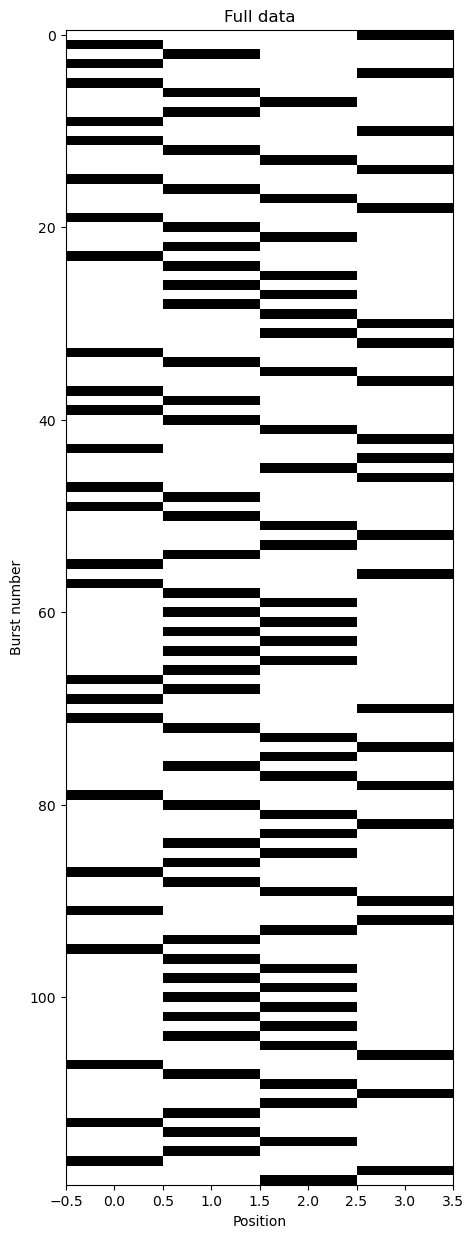

In [8]:
xtplot = np.zeros((len(full_movement_df), 1 + max(full_movement_df["position"])))
for i in full_movement_df.index:
    xtplot[i, full_movement_df.loc[i, "position"]] = 1

plt.figure(figsize = (5, 15))
plt.imshow(xtplot, aspect = "auto", interpolation = "none", cmap = "Greys")
plt.title("Full data")
plt.ylabel("Burst number")
plt.xlabel("Position")
plt.show()
#plt.close()

xtplot = np.zeros((len(pre_train_movement_df), 1 + max(pre_train_movement_df["position"])))
for i in pre_train_movement_df.index:
    xtplot[i, pre_train_movement_df.loc[i, "position"]] = 1

plt.figure(figsize = (5, 10))
plt.imshow(xtplot, aspect = "auto", interpolation = "none", cmap = "Greys")
plt.title("No stim")
plt.ylabel("Burst number")
plt.xlabel("Position")
#plt.show()
plt.close()


xtplot = np.zeros((len(train_movement_df), 1 + max(train_movement_df["position"])))
for i in train_movement_df.index:
    xtplot[i, train_movement_df.loc[i, "position"]] = 1

plt.figure(figsize = (5, 10))
plt.imshow(xtplot, aspect = "auto", interpolation = "none", cmap = "Greys")
plt.title("Stim")
plt.ylabel("Burst number")
plt.xlabel("Position")
#plt.show()
plt.close()


In [9]:

midway = (min(train_movement_df["frameno"]) + max(train_movement_df["frameno"]))/2

first_half_train_movement_df = train_movement_df.loc[train_movement_df["frameno"] < midway, :].reset_index()
second_half_train_movement_df = train_movement_df.loc[train_movement_df["frameno"] > midway, :].reset_index()

midway = (min(pre_train_movement_df["frameno"]) + max(pre_train_movement_df["frameno"]))/2

first_half_pre_train_movement_df = pre_train_movement_df.loc[pre_train_movement_df["frameno"] < midway, :].reset_index()
second_half_pre_train_movement_df = pre_train_movement_df.loc[pre_train_movement_df["frameno"] > midway, :].reset_index()

In [10]:
train_transition_df = m1da.build_transition_df(train_movement_df, world)
pre_train_transition_df = m1da.build_transition_df(pre_train_movement_df, world)
first_half_train_transition_df = m1da.build_transition_df(first_half_train_movement_df, world)
second_half_train_transition_df = m1da.build_transition_df(second_half_train_movement_df, world)

first_half_pre_train_transition_df = m1da.build_transition_df(first_half_pre_train_movement_df, world)
second_half_pre_train_transition_df = m1da.build_transition_df(second_half_pre_train_movement_df, world)

train_transition_df

,leftward,rightward,total,proportion left,object
0,3.0,7.0,10.0,0.300000,1
1,6.0,12.0,18.0,0.333333,0
2,11.0,6.0,17.0,0.647059,0
3,5.0,4.0,9.0,0.555556,0


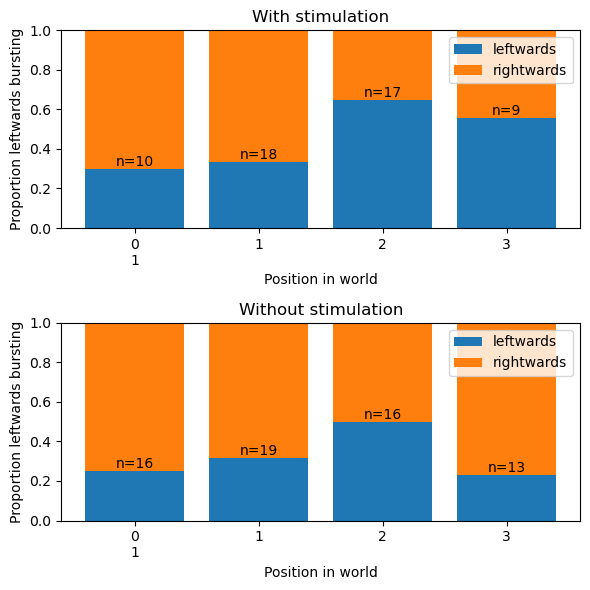

In [11]:
plt.figure(figsize = (6, 6))
ax = plt.subplot(211)
plt.title("With stimulation")
m1da.make_probability_bars(train_transition_df, world)

ax = plt.subplot(212)
plt.title("Without stimulation")
m1da.make_probability_bars(pre_train_transition_df, world)

plt.tight_layout()

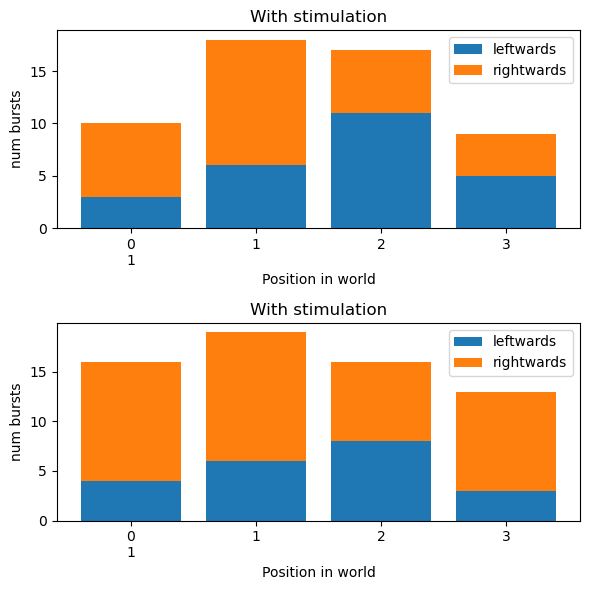

In [12]:
plt.figure(figsize = (6, 6))
ax = plt.subplot(211)
plt.title("With stimulation")
m1da.make_count_bars(train_transition_df, world)

ax = plt.subplot(212)
plt.title("Without stimulation")
m1da.make_count_bars(pre_train_transition_df, world)

plt.tight_layout()

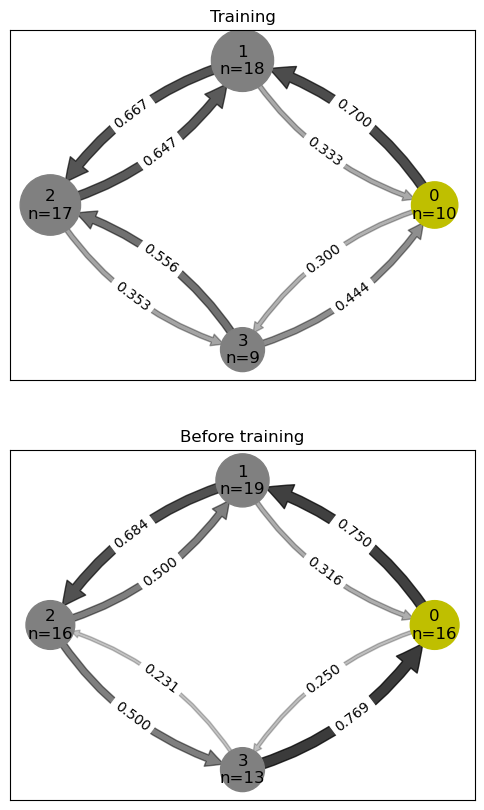

In [13]:
plt.figure(figsize = (6, 10))
plt.subplot(211)
plt.title("Training")
m1da.make_network_graph(train_transition_df, world)
plt.subplot(212)
plt.title("Before training")
m1da.make_network_graph(pre_train_transition_df, world)

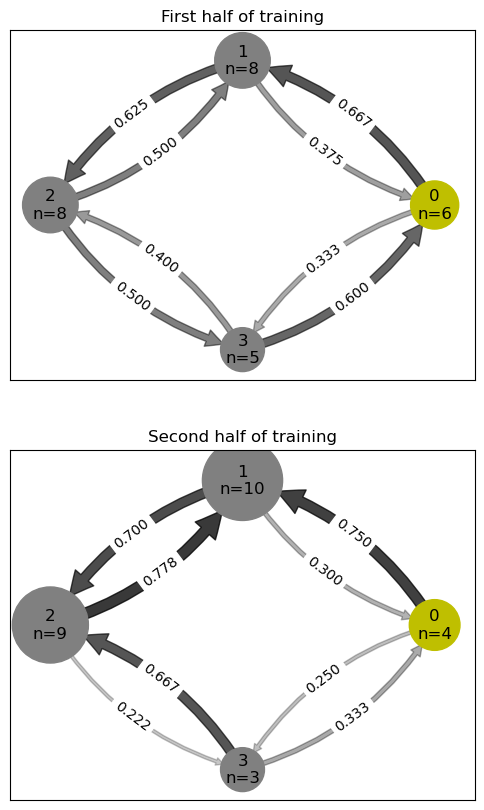

In [14]:
plt.figure(figsize = (6, 10))
plt.subplot(211)
plt.title("First half of training")
m1da.make_network_graph(first_half_train_transition_df, world)
plt.subplot(212)
plt.title("Second half of training")
m1da.make_network_graph(second_half_train_transition_df, world)

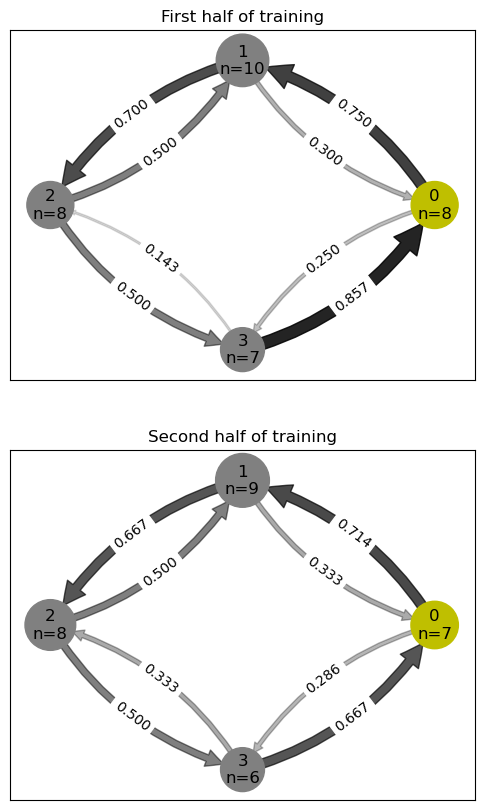

In [15]:
plt.figure(figsize = (6, 10))
plt.subplot(211)
plt.title("First half of training")
m1da.make_network_graph(first_half_pre_train_transition_df, world)
plt.subplot(212)
plt.title("Second half of training")
m1da.make_network_graph(second_half_pre_train_transition_df, world)

# Process the real data and get burst direction probabilities

In [16]:
display( train_movement_df)
display(pre_train_movement_df)
display(full_movement_df)

,frameno,time,position
0,18167342,1816.7342,2
1,18496539,1849.6539,1
2,18889557,1888.9557,0
3,19359338,1935.9338,1
4,19582340,1958.234,0
5,19786695,1978.6695,3
6,20147687,2014.7687,0
7,20468850,2046.885,1
8,20702426,2070.2426,2
9,20872280,2087.228,3


,frameno,time,position
0,50471,5.0471,3
1,175492,17.5492,0
2,436750,43.675,1
3,634126,63.4126,0
4,813068,81.3068,3
...,...,...,...
60,16740254,1674.0254,1
61,17107299,1710.7299,2
62,17293425,1729.3425,1
63,17663629,1766.3629,2


,frameno,time,position
0,50471,5.0471,3
1,175492,17.5492,0
2,436750,43.675,1
3,634126,63.4126,0
4,813068,81.3068,3
...,...,...,...
115,34374818,3437.4818,2
116,34778395,3477.8395,1
117,35235041,3523.5041,0
118,35449859,3544.9859,3


['events', 'groups', 'recording_id', 'settings', 'spikes', 'start_time', 'stop_time', 'well_id']
               time  channel  amplitude
0           -0.2263      428  -5.988275
1           -0.2263      368  -5.551394
2           -0.2197      343  -9.676657
3           -0.2157      883  -5.097673
4           -0.2152      754  -4.471618
...             ...      ...        ...
20518936  3605.0209      428   4.627533
20518937  3605.0223      742  -6.898822
20518938  3605.0272     1009  -4.675243
20518939  3605.0288      793  -4.612669
20518940  3605.0292      781   4.249669

[20518941 rows x 3 columns]


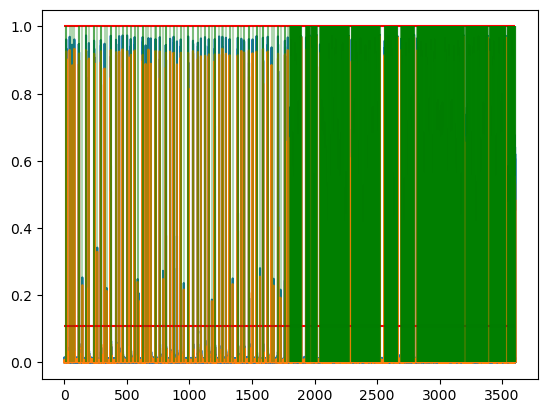

burst found in bin 1441 (time 14.18 s)
burst found in bin 1534 (time 15.11 s)
burst found in bin 1615 (time 15.92 s)
burst found in bin 4219 (time 41.96 s)
burst found in bin 6185 (time 61.62 s)
burst found in bin 7982 (time 79.59 s)
burst found in bin 11549 (time 115.26 s)
burst found in bin 11638 (time 116.15 s)
burst found in bin 11740 (time 117.17 s)
burst found in bin 14345 (time 143.22 s)
burst found in bin 17296 (time 172.73 s)
burst found in bin 17390 (time 173.67 s)
burst found in bin 17473 (time 174.50 s)
burst found in bin 19599 (time 195.76 s)
burst found in bin 23712 (time 236.89 s)
burst found in bin 23804 (time 237.81 s)
burst found in bin 23893 (time 238.70 s)
burst found in bin 26298 (time 262.75 s)
burst found in bin 29114 (time 290.91 s)
burst found in bin 29216 (time 291.93 s)
burst found in bin 29303 (time 292.80 s)
burst found in bin 32115 (time 320.92 s)
burst found in bin 33766 (time 337.43 s)
burst found in bin 37061 (time 370.38 s)
burst found in bin 37154 (ti

In [28]:
burst_list = m1da.find_bursts(filepath, filename, well_no, recording_no, burst_thresh = 1, datapath = datapath, stim_thresh = 1) # don't filter out stimulations by burst size - do it with events.
print(len(burst_list))

In [18]:
p = re.compile(r"stimulation\":\"\L<world_locs>\"", world_locs=set(world))

#this intermediate step isn't actually necessary
stimulation_events = events.loc[["stimulation" in i for i in events["eventmessage_decoded"]], :]
# for i in stimulation_events["eventmessage_decoded"]:
#     print(i)


big_stimulation_events = stimulation_events.loc[[not (p.search(i) is None) for i in stimulation_events["eventmessage_decoded"]], :]
big_stimulation_events.head()

,frameno,eventtype,eventid,eventmessage,frameno_adjusted,time,eventmessage_decoded
386,182255266,1,138,"b'{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""5"",""...",18889607,1888.9607,"{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""5"",""ph..."
387,182310844,1,139,"b'{""amp_mV"":""200"",""dac"":""2"",""end_stimulation"":...",18945185,1894.5185,"{""amp_mV"":""200"",""dac"":""2"",""end_stimulation"":""1..."
591,182948050,1,138,"b'{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""5"",""...",19582391,1958.2391,"{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""5"",""ph..."
592,183003627,1,139,"b'{""amp_mV"":""200"",""dac"":""2"",""end_stimulation"":...",19637968,1963.7968,"{""amp_mV"":""200"",""dac"":""2"",""end_stimulation"":""1..."
773,183513396,1,138,"b'{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""5"",""...",20147737,2014.7737,"{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""5"",""ph..."


[14.180000000000012, 15.110000000000014, 41.96000000000004, 61.62000000000006, 79.59000000000006, 115.2600000000001, 116.1500000000001, 117.1700000000001, 172.73000000000016, 173.67000000000016, 174.50000000000017, 195.7600000000002, 236.8900000000002, 237.81000000000023, 238.70000000000022, 290.91000000000025, 291.93000000000023, 320.92000000000024, 370.38000000000034, 412.56000000000034, 413.51000000000033, 437.56000000000034, 465.1200000000004, 466.0700000000004, 501.19000000000045, 502.15000000000043, 529.8400000000005, 531.0200000000004, 561.1700000000005, 562.4100000000005, 625.3500000000006, 626.2500000000006, 627.0600000000005, 649.0000000000006, 671.5300000000005, 690.9600000000006, 728.1500000000007, 729.0300000000007, 762.3900000000007, 810.6300000000007, 811.5700000000007, 812.4600000000007, 844.9700000000007, 872.9100000000008, 873.9100000000008, 899.8200000000007, 929.8800000000008, 930.8100000000009, 989.2800000000009, 1027.8200000000008, 1028.8100000000009, 1066.7200000

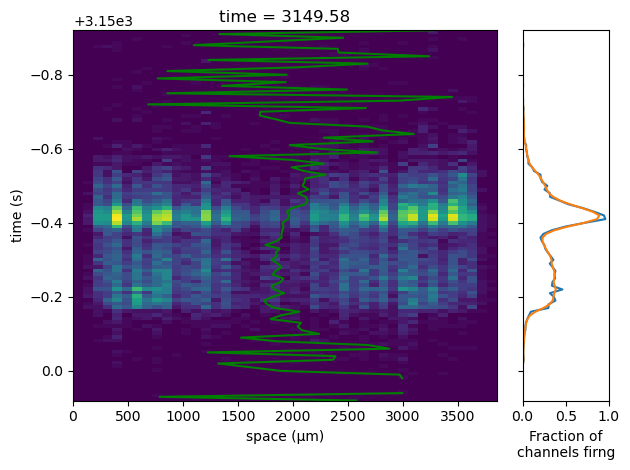

-19.290133641313332


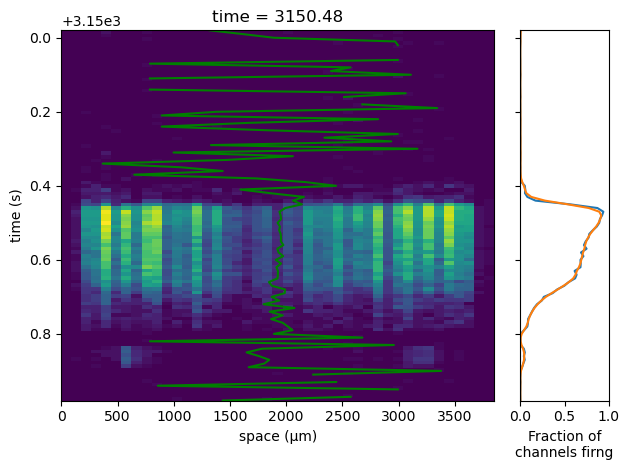

-207.1248812915478


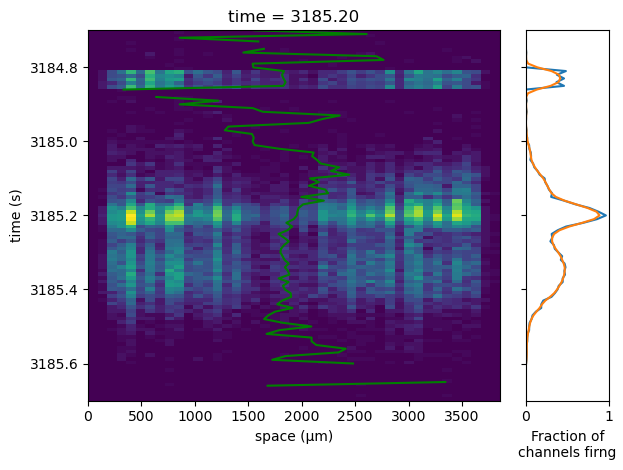

-396.1082494115833


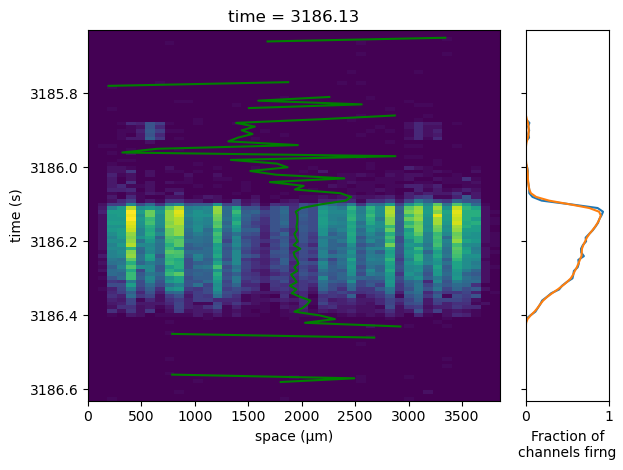

-505.94696969696975


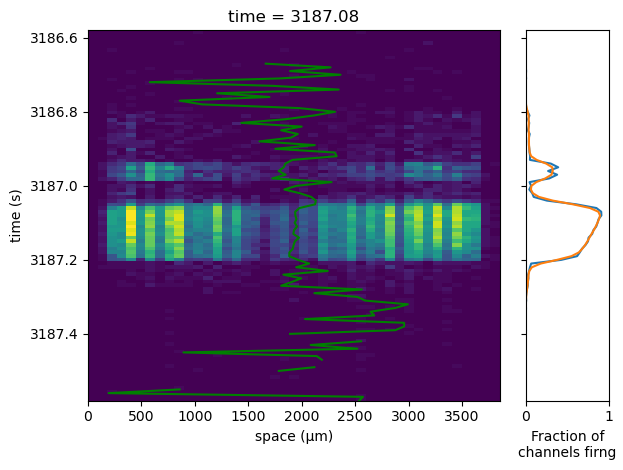

-148.26077678190381


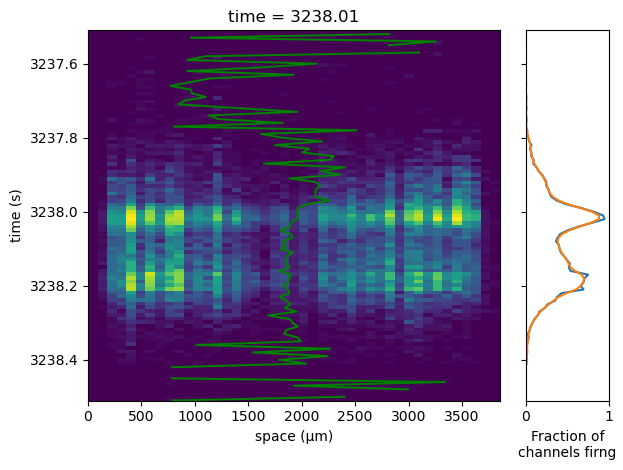

324.32009750318934


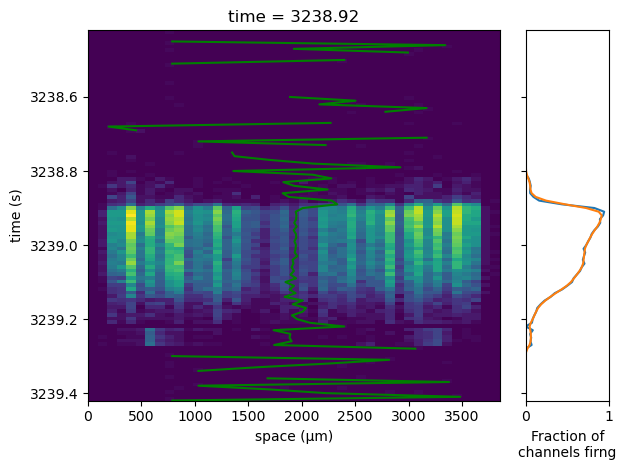

71.29149011299432


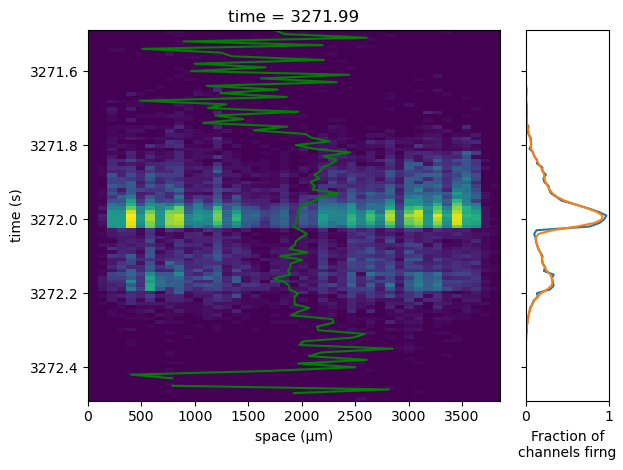

-241.19194577040457


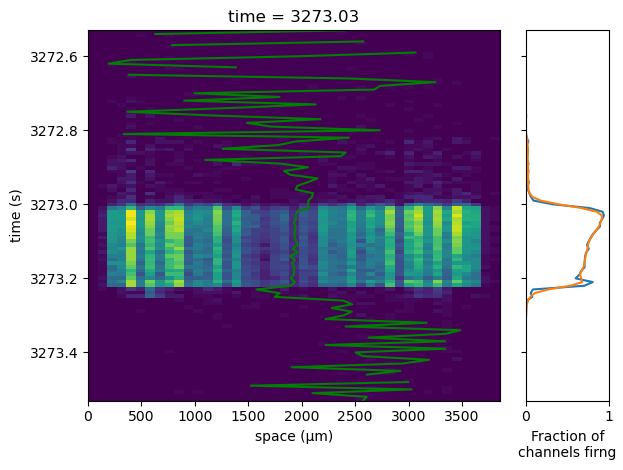

-118.16102574077672


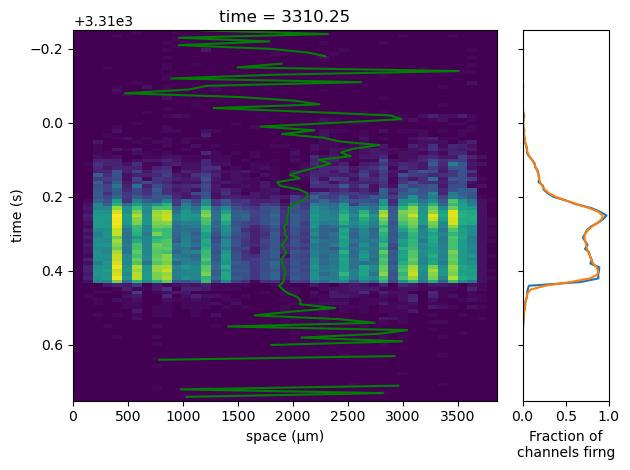

-278.8781146049082


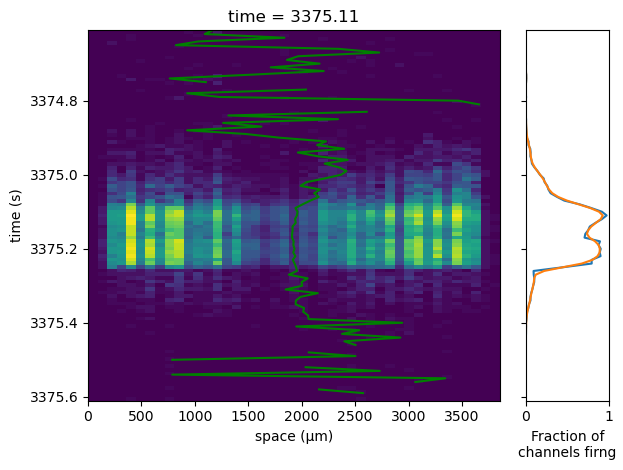

-392.2343739643402


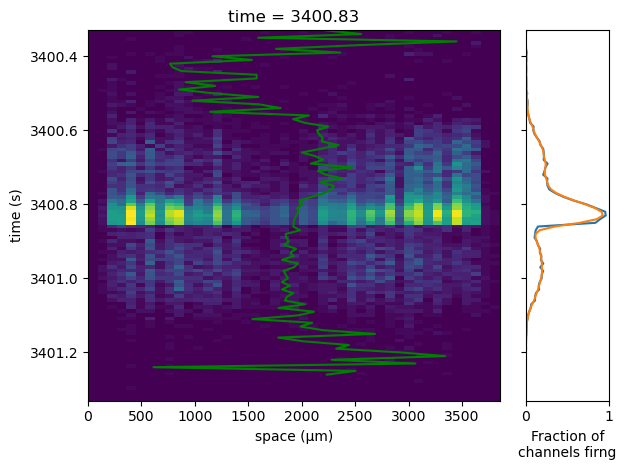

-210.09828476016992


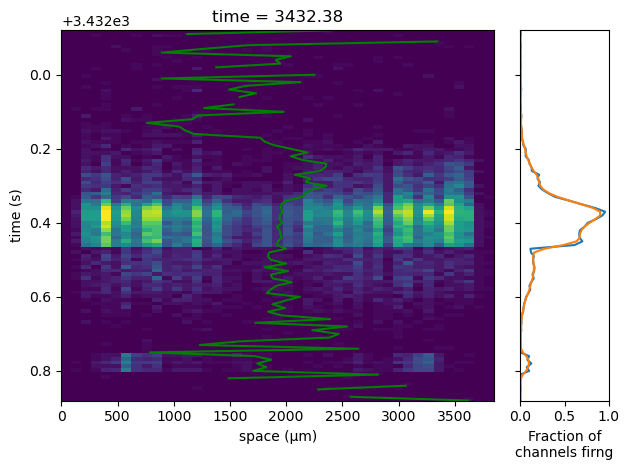

-416.41489361702133


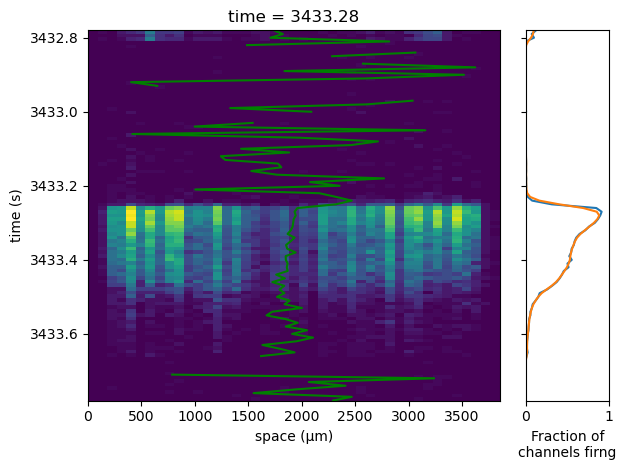

-524.1914191419141


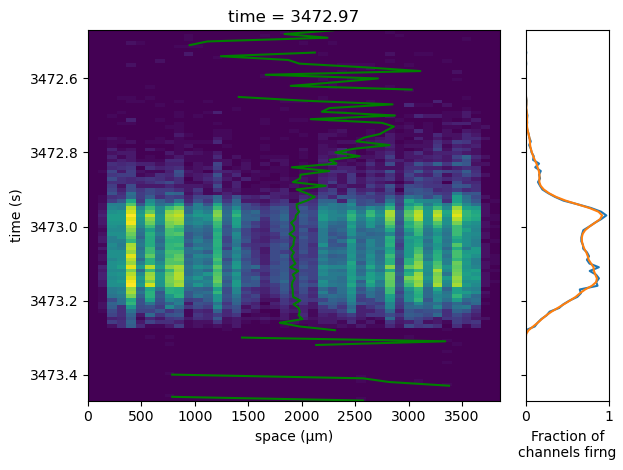

-315.2711479771499


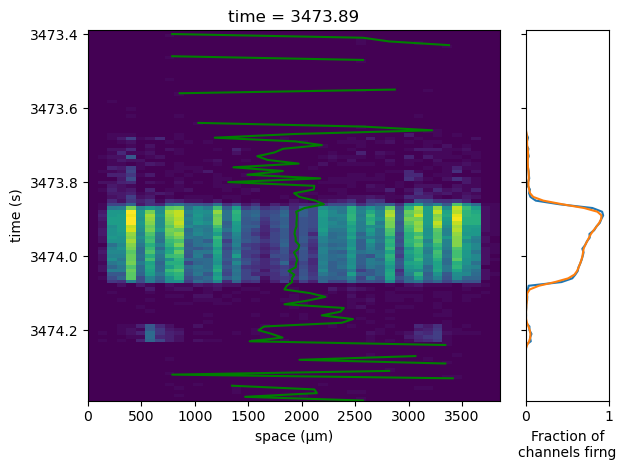

-172.36559139784936


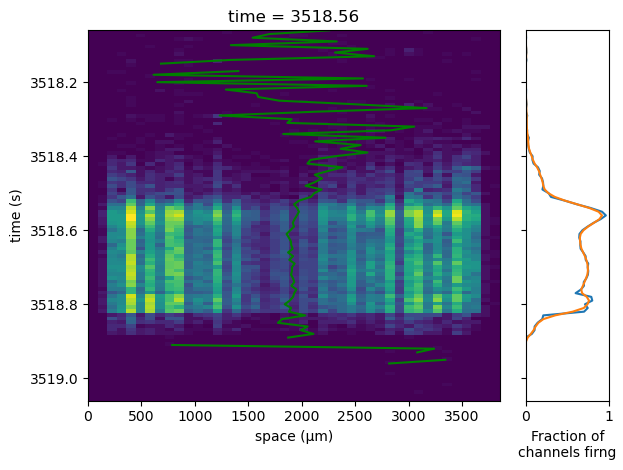

-98.52802900933966


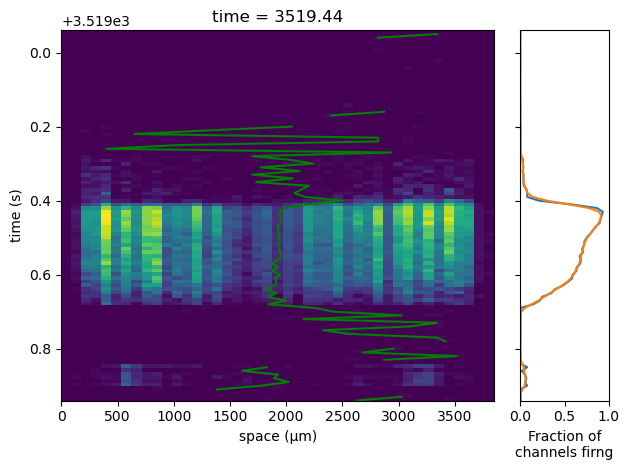

-227.66335836909866


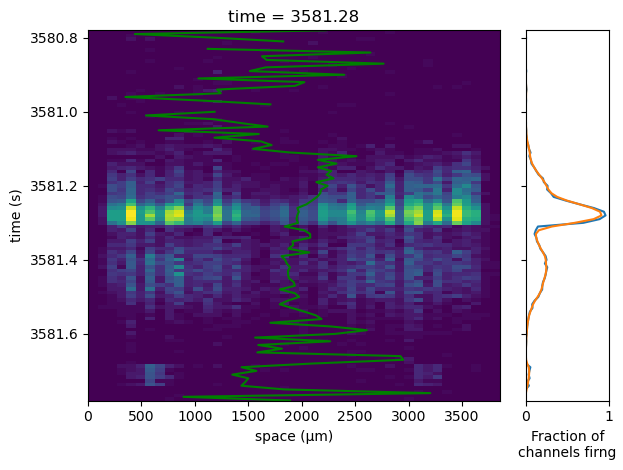

-193.06803822460893


In [27]:
print([i.time for i in trimmed_burst_list])
for i in list(trimmed_burst_list)[-20:-1]:
    i.plot()
    print(i.burst_direction(0.1))

In [19]:
trimmed_burst_list = list()
for i, burst in enumerate(burst_list):
    time = burst.time
    sub_big_stimulation_events = big_stimulation_events.loc[big_stimulation_events["time"] < time + 0.5].reset_index(drop = True)
    if len(sub_big_stimulation_events) > 0 and "start_stimulation" in sub_big_stimulation_events.loc[len(sub_big_stimulation_events) - 1, "eventmessage_decoded"]:
        #print(sub_big_stimulation_events.loc[len(sub_big_stimulation_events) - 1, :])
        print("removing burst at time " + str(time))
    else:
        trimmed_burst_list.append(burst)

removing burst at time 1888.5300000000016
removing burst at time 1889.6400000000017
removing burst at time 1890.8000000000018
removing burst at time 1891.9000000000017
removing burst at time 1893.0000000000016
removing burst at time 1957.8300000000017
removing burst at time 1958.9300000000017
removing burst at time 1960.0300000000018
removing burst at time 1961.1900000000016
removing burst at time 1962.2900000000018
removing burst at time 2014.3900000000017
removing burst at time 2015.4900000000018
removing burst at time 2016.6000000000017
removing burst at time 2017.6900000000019
removing burst at time 2018.8100000000018
removing burst at time 2270.550000000002
removing burst at time 2271.660000000002
removing burst at time 2272.760000000002
removing burst at time 2273.870000000002
removing burst at time 2275.020000000002
removing burst at time 2517.160000000002
removing burst at time 2518.260000000002
removing burst at time 2519.4200000000023
removing burst at time 2520.530000000002


In [26]:
print([i.time for i in trimmed_burst_list])
for i in list(trimmed_burst_list)[-20:0]:
    i.plot()
    print(i.burst_direction(0.1))

[14.180000000000012, 15.110000000000014, 41.96000000000004, 61.62000000000006, 79.59000000000006, 115.2600000000001, 116.1500000000001, 117.1700000000001, 172.73000000000016, 173.67000000000016, 174.50000000000017, 195.7600000000002, 236.8900000000002, 237.81000000000023, 238.70000000000022, 290.91000000000025, 291.93000000000023, 320.92000000000024, 370.38000000000034, 412.56000000000034, 413.51000000000033, 437.56000000000034, 465.1200000000004, 466.0700000000004, 501.19000000000045, 502.15000000000043, 529.8400000000005, 531.0200000000004, 561.1700000000005, 562.4100000000005, 625.3500000000006, 626.2500000000006, 627.0600000000005, 649.0000000000006, 671.5300000000005, 690.9600000000006, 728.1500000000007, 729.0300000000007, 762.3900000000007, 810.6300000000007, 811.5700000000007, 812.4600000000007, 844.9700000000007, 872.9100000000008, 873.9100000000008, 899.8200000000007, 929.8800000000008, 930.8100000000009, 989.2800000000009, 1027.8200000000008, 1028.8100000000009, 1066.7200000

In [21]:
def get_position_when_burst(burst: Burst, movement_df: pd.DataFrame)-> int:
    time = burst.time

    position = -1
    

    for i in movement_df.index:
        previous_position = position

        transition_time = movement_df.loc[i, "time"]
        position = movement_df.loc[i, "position"]

        if time < transition_time:
            return previous_position
    

    return position
    

3
3
0
1
0
3
3
3
1
1
1
2
1
1
1
3
3
0
2
3
3
0
1
1
2
2
3
3
0
0
0
0
0
1
2
1
2
2
1
3
3
3
2
3
3
0
1
1
3
0
0
1
1
0
1
1
2
2
0
0
3
2
2
3
0
0
0
0
1
2
2
3
2
1
1
3
3
3
0
0
1
1
1
1
1
1
1
2
1
1
2
2
1
1
0
0
0
0
3
3
0
0
3
3
3
2
1
1
2
2
3
3
0
1
1
2
2
3
3
3
2
2
2
0
0
1
2
2
3
0
0
0
3
3
2
1
1
1
0
0
1
1
2
2
1
2
2
1
1
2
1
1
2
2
3
3
3
1
1
2
2
3
1
0
1
1
2
2
1
1
3
3


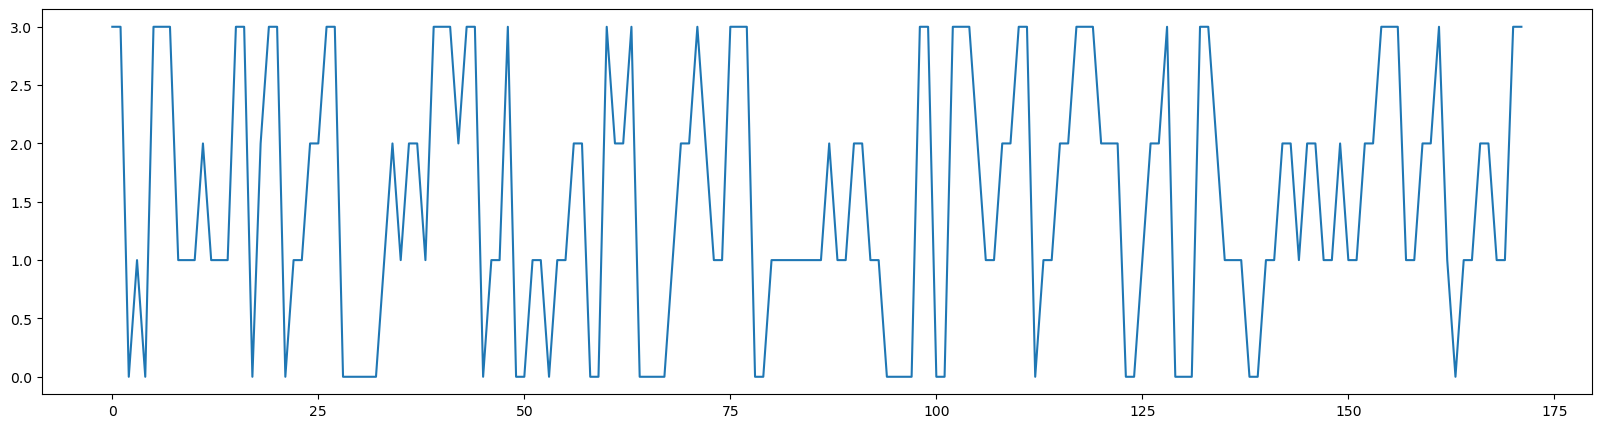

In [22]:
for burst in trimmed_burst_list:
    print(get_position_when_burst(burst, full_movement_df))

plt.figure(figsize = (20, 5))
plt.plot([get_position_when_burst(i, full_movement_df) for i in trimmed_burst_list])

In [23]:
raw_data_transition_df = pd.DataFrame(columns = ["leftward", "rightward", "total", "proportion left", "object"], index = range(0, len(world)))
pre_train_raw_data_transition_df = pd.DataFrame(columns = ["leftward", "rightward", "total", "proportion left", "object"], index = range(0, len(world)))
train_raw_data_transition_df = pd.DataFrame(columns = ["leftward", "rightward", "total", "proportion left", "object"], index = range(0, len(world)))
raw_data_transition_df["leftward"] = 0
raw_data_transition_df["rightward"] = 0
train_raw_data_transition_df["leftward"] = 0
train_raw_data_transition_df["rightward"] = 0
pre_train_raw_data_transition_df["leftward"] = 0
pre_train_raw_data_transition_df["rightward"] = 0


raw_data_transition_df["object"] = list(world)
train_raw_data_transition_df["object"] = list(world)
pre_train_raw_data_transition_df["object"] = list(world)

display(train_raw_data_transition_df)
display(raw_data_transition_df)
for burst in trimmed_burst_list:
    burst_direction = burst.burst_direction()
    position = get_position_when_burst(burst, full_movement_df)
    if burst_direction < 0:
        raw_data_transition_df.loc[position, "leftward"] += 1
        if burst.time < train_time:
            pre_train_raw_data_transition_df.loc[position, "leftward"] += 1
        else:
            train_raw_data_transition_df.loc[position, "leftward"] += 1
    else:
        raw_data_transition_df.loc[position, "rightward"] += 1
        if burst.time < train_time:
            pre_train_raw_data_transition_df.loc[position, "rightward"] += 1
        else:
            train_raw_data_transition_df.loc[position, "rightward"] += 1
    
raw_data_transition_df["total"] = raw_data_transition_df["leftward"] + raw_data_transition_df["rightward"] 
raw_data_transition_df["proportion left"] = raw_data_transition_df["leftward"]/raw_data_transition_df["total"]

train_raw_data_transition_df["total"] = train_raw_data_transition_df["leftward"] + train_raw_data_transition_df["rightward"] 
train_raw_data_transition_df["proportion left"] = train_raw_data_transition_df["leftward"]/train_raw_data_transition_df["total"]

pre_train_raw_data_transition_df["total"] = pre_train_raw_data_transition_df["leftward"] + pre_train_raw_data_transition_df["rightward"] 
pre_train_raw_data_transition_df["proportion left"] = pre_train_raw_data_transition_df["leftward"]/pre_train_raw_data_transition_df["total"]

raw_data_transition_df



,leftward,rightward,total,proportion left,object
0,0,0,NaN,NaN,1
1,0,0,NaN,NaN,0
2,0,0,NaN,NaN,0
3,0,0,NaN,NaN,0


,leftward,rightward,total,proportion left,object
0,0,0,NaN,NaN,1
1,0,0,NaN,NaN,0
2,0,0,NaN,NaN,0
3,0,0,NaN,NaN,0


,leftward,rightward,total,proportion left,object
0,36,0,36,1.000000,1
1,53,1,54,0.981481,0
2,37,3,40,0.925000,0
3,41,1,42,0.976190,0


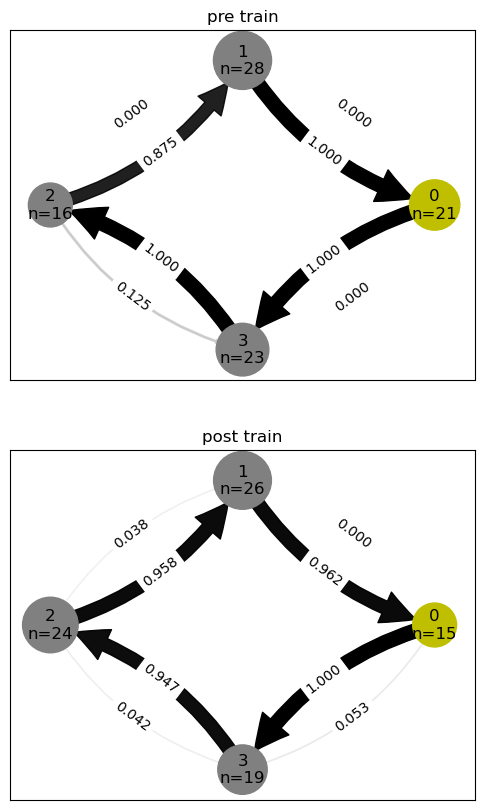

In [24]:
plt.figure(figsize = (6, 10))
plt.subplot(211)
plt.title("pre train")
m1da.make_network_graph(pre_train_raw_data_transition_df, world)

plt.subplot(212)
plt.title("post train")
m1da.make_network_graph(train_raw_data_transition_df, world)
